# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Domingo, Judiele Fatima 
- _Student No._: 2023-05167
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="Bessel.png" alt="Bessel functions for m=0,1,2">

**Figure 1:** Plotted Bessel Functions for m =1,2,3

Figure 1 shows the Bessel fuctions for orders m=1,2,3. All functions show oscillations with amplitude decreasing as x increases. 

<img src="diff.png" alt="Diffraction Pattern">

**Figure 2:** Diffraction Pattern of a Light source with wavelength of 500 nm

Figure 2 shows the diffraction pattern of a light source with $\lambda = 500 nm$. The pattern has a bright central maximum with rings progressively decreasing in intensity. 

<img src="mc.png" alt="Monte Carlo vs. Scipy">

**Figure 3:** Gamma Function Evaluated using Monte Carlo Importance Sampling vs. scipy.special.gamma

Figure 3 compares the Gamma function of Monte Carlo Importance Sampling estimates with reference values using Scipy.
### Report discussion

The bright spot in fig. 2 shows the central maximum while the rings are alternating minima and maxima created by interference. The figure shows the diffraction limit of a telescope, a point-like image such as a far-away star would look like the diffraction pattern when viewed through a telescope. 

The previous Monte Carlo method used uniform sampling which generated random points with equal probability in the integration interval. Importance sampling uses a non-uniform probability sampling (exponential distribution) to create more random points in important regions/ regions that contribute more to the integral. The points are weighted by a ratio of the integrand and the distribution. 

Sampling distribution should cover all regions that contribute to the integral. If the wrong distribution, weights might become very large making the estimate unreliable. 

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy

### Problem 1: Diffraction limit of a telescope

![Screenshot 2026-11-09 at 5.08.50 PM.png](DiffLimitTelescopeNeumann5-4.png)


Hint 1: You may find it useful to know that $\lim_{x→0} J_1(x)/x = 1/2$ 

Hint 2: The central
spot in the diffraction pattern is so bright that it may be difficult to see the rings around
it on the computer screen. If you run into this problem a simple way to deal with it is to
use one of the other color schemes for density plots described in Section 3.3. The “hot”
scheme works well. For a more sophisticated solution to the problem, the imshow function has an additional argument vmax that allows you to set the value that corresponds
to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in x with value 0.1, or any greater value, will produce the brightest (most positive) color on the screen. By lowering the `vmax` value, you can reduce the total range of
values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. (There is also a `vmin` argument that can
be used to set the value that corresponds to the dimmest (most negative) color.) For this
exercise a value of `vmax=0.01` appears to work well.

Report discussion: Explain the figure

#### PART A

---

In [2]:
from Bessel import J
X = np.linspace(0,20,1001) #1000 point grid from x=0 to x=20
#calculates bessel function for m=0,1,2
J0 = np.array([J(0, x) for x in X])
J1 = np.array([J(1,x) for x in X])
J2 = np.array([J(2,x) for x in X])

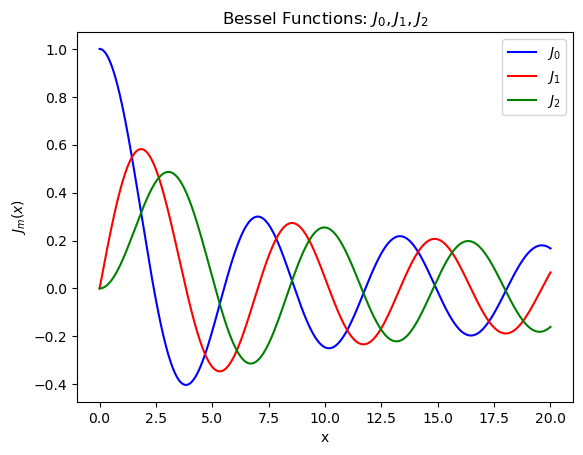

In [3]:
plt.plot(X,J0, color='blue', label=r'$J_0$')
plt.plot(X, J1, color='red', label=r'$J_1$')
plt.plot(X, J2, color = 'green', label=r'$J_2$')
plt.xlabel('x')
plt.ylabel(r'$J_m(x)$')
plt.title(r"Bessel Functions: $J_0, J_1,J_2$")
plt.legend(loc='upper right')
plt.show()

#### PART B

---

/home/jovyan/Submissions/AP155_TX1_1sAY2627/Domingo_Judiele/12_MoreIntegration/Diffraction_pattern.py:20: RuntimeWarning: invalid value encountered in divide
  I=(j1_grid/kR)**2


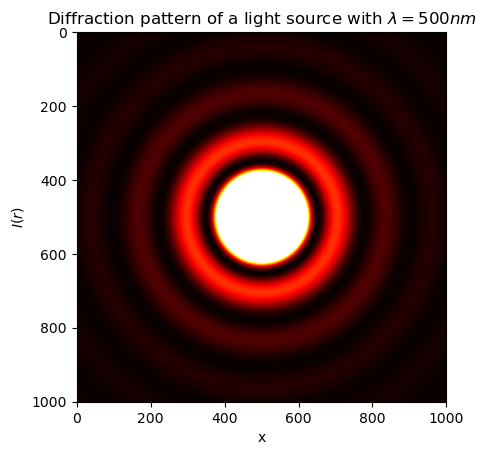

In [4]:
from Diffraction_pattern import density_plot
density_plot(r=1e-6)

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [1,5]. $ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$ Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$



Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

In [10]:
"""
For a exponential distribution
F(t) = integral from 0 to t of e**(-s); setting F(t)=1-e**(-t)
let i = F(t)
e**(-t)=1-u
t = -ln(1-u)

g(t) = t**(z-1)*np.exp**(-t)/np.exp**(-t)
g(t) = t**(z-1) #t from 0 to inf
"""
def g(t,z):
    return t**(z-1) #importance weighed function

def montecarlo_importance(z,n): #modified gezerlis
    np.random.seed(314159)
    u = np.random.uniform(0,1,n)
    t = -np.log(1-u)
    fs = g(t,z)
    fbar = np.mean(fs)
    err = np.std(fs, ddof=1) / np.sqrt(n)
    return fbar, err

In [11]:
Z=np.linspace(1,5,10000)
mc = [montecarlo_importance(z, 10000)[0] for z in Z]

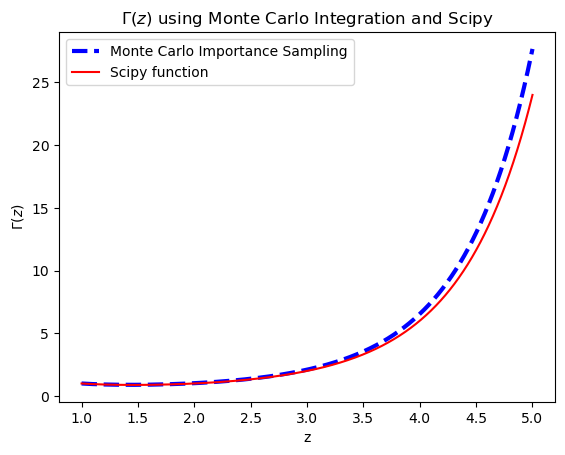

In [12]:
plt.title(r'$\Gamma (z)$ using Monte Carlo Integration and Scipy')
plt.plot(Z, mc, color = 'blue', ls = '--', lw=3,label = "Monte Carlo Importance Sampling")
plt.xlabel('z')
plt.ylabel(r'$\Gamma(z)$')
plt.plot(z,scipy.special.gamma(z), color='red', label = "Scipy function")
plt.legend()
plt.show()